In [2]:
!unzip -q /content/archive.zip -d /content/data && ls /content/data/head_ct/head_ct | wc -l

200


In [3]:
import numpy as np, pandas as pd, random, torch, torch.nn as nn
from PIL import Image
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from torch.amp import GradScaler, autocast
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

IMG_DIR = "/content/data/head_ct/head_ct"
LABELS_CSV = "/content/data/labels.csv"
IMG_SIZE, BATCH, EPOCHS, LR, SEED = 224, 16, 20, 1e-4, 42
DEVICE = "cuda"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

labels = pd.read_csv(LABELS_CSV)
labels.columns = [c.strip() for c in labels.columns]
labels["path"] = labels["id"].apply(lambda i: f"{IMG_DIR}/{int(i):03d}.png")

train_df, tmp = train_test_split(labels, test_size=0.30, stratify=labels["hemorrhage"], random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.50, stratify=tmp["hemorrhage"], random_state=SEED)
print(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")

MEAN, STD = [0.485,0.456,0.406], [0.229,0.224,0.225]

class DS(Dataset):
    def __init__(self, df, aug=False):
        self.df = df.reset_index(drop=True)
        ops = [transforms.RandomHorizontalFlip(), transforms.RandomRotation(15),
               transforms.RandomAffine(0, translate=(0.05,0.05), scale=(0.9,1.1)),
               transforms.ColorJitter(brightness=0.2, contrast=0.2)] if aug else []
        self.tf = transforms.Compose([transforms.Resize((IMG_SIZE,IMG_SIZE)), *ops,
                                      transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        return self.tf(Image.open(r["path"]).convert("RGB")), torch.tensor(r["hemorrhage"], dtype=torch.float32)

train_dl = DataLoader(DS(train_df, aug=True), batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=True)
val_dl   = DataLoader(DS(val_df),   batch_size=BATCH, num_workers=2, pin_memory=True)
test_dl  = DataLoader(DS(test_df),  batch_size=BATCH, num_workers=2, pin_memory=True)

model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
model.classifier = nn.Linear(model.classifier.in_features, 1)
model = model.to(DEVICE)

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
loss_fn = nn.BCEWithLogitsLoss()
scaler = GradScaler("cuda")

def evaluate(dl):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in dl:
            x = x.to(DEVICE, non_blocking=True)
            with autocast("cuda"): logit = model(x).squeeze(1)
            ps.append(torch.sigmoid(logit).float().cpu().numpy()); ys.append(y.numpy())
    y_true, y_prob = np.concatenate(ys), np.concatenate(ps)
    auc = roc_auc_score(y_true, y_prob)
    tn, fp, fn, tp = confusion_matrix(y_true, (y_prob>=0.5).astype(int)).ravel()
    return auc, tp/(tp+fn+1e-9), tn/(tn+fp+1e-9), (tn,fp,fn,tp)

best = 0.0
for ep in range(1, EPOCHS+1):
    model.train(); running = 0.0
    for x, y in train_dl:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        opt.zero_grad()
        with autocast("cuda"):
            loss = loss_fn(model(x).squeeze(1), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        running += loss.item() * x.size(0)
    sched.step()
    auc, sens, spec, _ = evaluate(val_dl)
    print(f"ep {ep:2d}  loss={running/len(train_dl.dataset):.4f}  val_auc={auc:.4f}  sens={sens:.3f}  spec={spec:.3f}")
    if auc > best:
        best = auc; torch.save(model.state_dict(), "/content/best.pt")

model.load_state_dict(torch.load("/content/best.pt"))
auc, sens, spec, cm = evaluate(test_dl)
print(f"\n=== TEST ===  AUC={auc:.4f}  sens={sens:.3f}  spec={spec:.3f}  cm(TN,FP,FN,TP)={cm}")

train=140  val=30  test=30
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 169MB/s]


ep  1  loss=0.6624  val_auc=0.8222  sens=0.267  spec=1.000
ep  2  loss=0.4652  val_auc=0.9556  sens=0.733  spec=1.000
ep  3  loss=0.3200  val_auc=0.9822  sens=0.867  spec=1.000
ep  4  loss=0.1894  val_auc=0.9822  sens=0.933  spec=0.867
ep  5  loss=0.1471  val_auc=0.9956  sens=1.000  spec=0.933
ep  6  loss=0.1113  val_auc=1.0000  sens=1.000  spec=0.867
ep  7  loss=0.0504  val_auc=1.0000  sens=1.000  spec=1.000
ep  8  loss=0.0504  val_auc=1.0000  sens=1.000  spec=1.000
ep  9  loss=0.0690  val_auc=0.9956  sens=1.000  spec=0.933
ep 10  loss=0.0446  val_auc=0.9956  sens=1.000  spec=0.867
ep 11  loss=0.0280  val_auc=1.0000  sens=1.000  spec=0.867
ep 12  loss=0.0642  val_auc=1.0000  sens=1.000  spec=0.867
ep 13  loss=0.0354  val_auc=1.0000  sens=1.000  spec=0.867
ep 14  loss=0.0262  val_auc=1.0000  sens=1.000  spec=0.933
ep 15  loss=0.0229  val_auc=1.0000  sens=1.000  spec=0.933
ep 16  loss=0.0233  val_auc=1.0000  sens=1.000  spec=0.933
ep 17  loss=0.0217  val_auc=1.0000  sens=1.000  spec=0.8

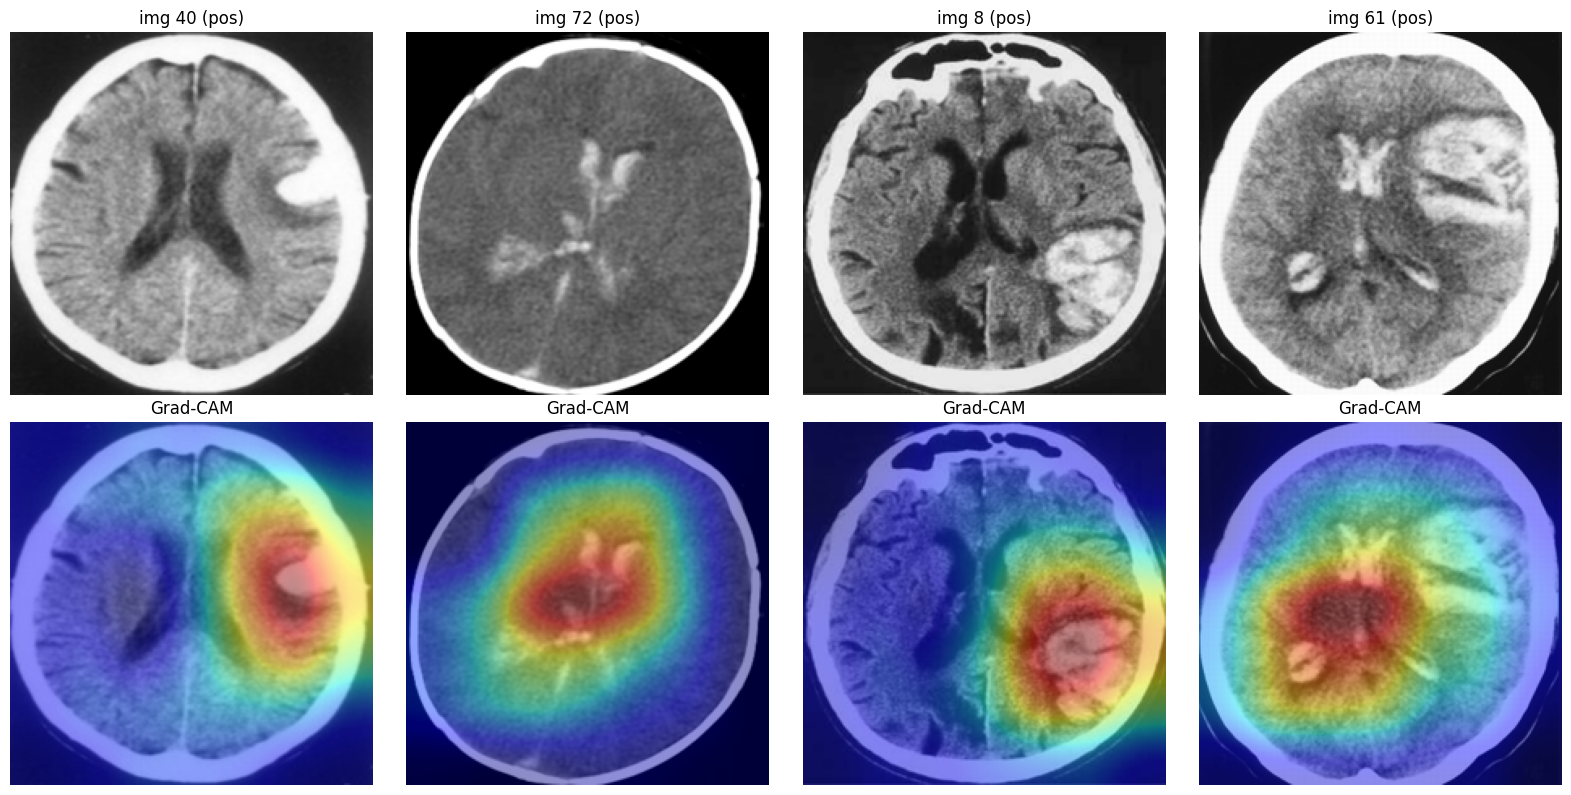

In [4]:
import matplotlib.pyplot as plt
target_layer = model.features.denseblock4
acts, grads = {}, {}
h1 = target_layer.register_forward_hook(lambda m,i,o: acts.update(v=o.detach()))
h2 = target_layer.register_full_backward_hook(lambda m,gi,go: grads.update(v=go[0].detach()))

model.eval()
show = test_df[test_df["hemorrhage"]==1].head(4).reset_index(drop=True)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, row in show.iterrows():
    pil = Image.open(row["path"]).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    x = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])(pil).unsqueeze(0).to(DEVICE)
    x.requires_grad_(True)
    model.zero_grad()
    model(x).squeeze().backward()
    a, g = acts["v"][0], grads["v"][0]
    w = g.mean(dim=(1,2))
    cam = torch.relu((w[:,None,None]*a).sum(0))
    cam = ((cam - cam.min()) / (cam.max() - cam.min() + 1e-9)).cpu().numpy()
    axes[0,i].imshow(pil, cmap="gray"); axes[0,i].set_title(f"img {row['id']} (pos)"); axes[0,i].axis("off")
    axes[1,i].imshow(pil, cmap="gray")
    axes[1,i].imshow(np.array(Image.fromarray((cam*255).astype(np.uint8)).resize((IMG_SIZE, IMG_SIZE))), cmap="jet", alpha=0.45)
    axes[1,i].set_title("Grad-CAM"); axes[1,i].axis("off")
h1.remove(); h2.remove()
plt.tight_layout(); plt.savefig("/content/gradcam.png", dpi=120, bbox_inches="tight"); plt.show()

In [1]:
import os, json
os.makedirs("/root/.kaggle", exist_ok=True)
with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump({"username": "neurosentry", "key": "KGAT_cff7e7312a6c67b1c72b49bd441c5f0e"}, f)
os.chmod("/root/.kaggle/kaggle.json", 0o600)
!pip install -q kaggle
!kaggle datasets list -s qureai | head -5

ref                     title                       size  lastUpdated                 downloadCount  voteCount  usabilityRating  
----------------------  -------------------  -----------  --------------------------  -------------  ---------  ---------------  
kmader/headctreads      QureAI HeadCT Reads        11461  2018-05-15 06:33:13.717000             91          2  0.29411766       
crawford/qureai-headct  Qure.ai HeadCT       27565296852  2018-05-18 03:48:28.010000          20961         19  0.3529412        


In [4]:
!kaggle datasets download -d kmader/headctreads -p /content/labels --unzip
!ls /content/labels
import pandas as pd
print("=== prediction_probabilities.csv ===")
print(pd.read_csv("/content/labels/prediction_probabilities.csv").head(3))
print("\ncolumns:", list(pd.read_csv("/content/labels/prediction_probabilities.csv").columns))

Dataset URL: https://www.kaggle.com/datasets/kmader/headctreads
License(s): CC-BY-NC-SA-4.0
100% 11.2k/11.2k [00:00<00:00, 36.1MB/s]

prediction_probabilities.csv  reads.csv
=== prediction_probabilities.csv ===
           name Category_New   ICH   IPH   IVH   SDH   EDH   SAH  \
0  CQ500-CT-427           B2  0.99  0.46  0.07  0.36  0.03  0.33   
1  CQ500-CT-181           B2  0.99  0.63  0.00  0.68  0.22  0.22   
2   CQ500-CT-99           B1  0.25  0.01  0.00  0.08  0.00  0.12   

   CalvarialFracture  MassEffect  MidlineShift  
0           0.029752        0.62          0.20  
1           0.975000        1.00          1.00  
2           0.029752        0.22          0.02  

columns: ['name', 'Category_New', 'ICH', 'IPH', 'IVH', 'SDH', 'EDH', 'SAH', 'CalvarialFracture', 'MassEffect', 'MidlineShift']


In [8]:
import os, zipfile, time
t0 = time.time()
os.makedirs("/content/cq500_data", exist_ok=True)
with zipfile.ZipFile("/content/cq500/qureai-headct.zip") as z:
    z.extractall("/content/cq500_data")
print(f"extracted in {time.time()-t0:.1f}s")
!ls /content/cq500_data | head -5
!echo "---"
!du -sh /content/cq500_data /content/cq500
!echo "---"
!rm /content/cq500/qureai-headct.zip
!echo "zip deleted"
!df -h /content

extracted in 483.8s
prediction_probabilities.csv
qct01
qct02
qct03
qct04
---
39G	/content/cq500_data
26G	/content/cq500
---
zip deleted
Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   86G   27G  77% /
